<a href="https://colab.research.google.com/github/sherly2212/customer-segmentation/blob/main/customer_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

customer = pd.read_csv("customer_details.csv")
customer.columns = customer.columns.str.strip().str.lower().str.replace(" ", "_", regex=False)
print(customer.shape)
customer.head()

(3900, 18)


,customer_id,age,gender,item_purchased,category,purchase_amount_(usd),location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,promo_code_used,previous_purchases,payment_method,frequency_of_purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [22]:
customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             3900 non-null   int64  
 1   age                     3900 non-null   int64  
 2   gender                  3900 non-null   object 
 3   item_purchased          3900 non-null   object 
 4   category                3900 non-null   object 
 5   purchase_amount_(usd)   3900 non-null   int64  
 6   location                3900 non-null   object 
 7   size                    3900 non-null   object 
 8   color                   3900 non-null   object 
 9   season                  3900 non-null   object 
 10  review_rating           3900 non-null   float64
 11  subscription_status     3900 non-null   object 
 12  shipping_type           3900 non-null   object 
 13  discount_applied        3900 non-null   object 
 14  promo_code_used         3900 non-null   

In [23]:
customer.isnull().sum()

,0
customer_id,0
age,0
gender,0
item_purchased,0
category,0
purchase_amount_(usd),0
location,0
size,0
color,0
season,0


In [24]:
customer.duplicated().sum()

np.int64(0)

In [25]:
customer.duplicated().sum()


np.int64(0)

In [26]:
customer.describe()

,customer_id,age,purchase_amount_(usd),review_rating,previous_purchases
count,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.749949,25.351538
std,1125.977353,15.207589,23.685392,0.716223,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.700000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


In [27]:
customer = customer.rename(columns={"purchase_amount_(usd)": "purchase_amount"})

In [28]:
customer.groupby("category")["purchase_amount"].agg(["count", "sum", "mean"]).round(1).sort_values("sum", ascending=False)

,count,sum,mean
category,,,
Clothing,1737,104264,60.0
Accessories,1240,74200,59.8
Footwear,599,36093,60.3
Outerwear,324,18524,57.2


In [29]:
customer["age_group"] = pd.cut(customer["age"], bins=[17, 25, 35, 45, 55, 70], labels=["18-25", "26-35", "36-45", "46-55", "56-70"])
customer.groupby("age_group", observed=True)["purchase_amount"].agg(["count", "mean"]).round(1)

,count,mean
age_group,,
18-25,571,60.6
26-35,742,59.8
36-45,729,59.3
46-55,753,60.6
56-70,1105,59.1


In [30]:
customer["frequency_of_purchases"].value_counts()

,count
frequency_of_purchases,
Every 3 Months,584
Annually,572
Quarterly,563
Monthly,553
Bi-Weekly,547
Fortnightly,542
Weekly,539


In [31]:
freq_map = {
    "Weekly": 5, "Fortnightly": 4, "Bi-Weekly": 4, "Monthly": 3,
    "Quarterly": 2, "Every 3 Months": 2, "Annually": 1
}
customer["freq_score"] = customer["frequency_of_purchases"].map(freq_map)
customer["freq_score"].isnull().sum()

np.int64(0)

In [32]:
def segmen(row):
    if row["freq_score"] >= 4 and row["previous_purchases"] >= 25:
        return "Loyal"
    elif row["previous_purchases"] >= 25:
        return "Berpotensi"
    elif row["freq_score"] >= 4:
        return "Baru Aktif"
    else:
        return "Jarang Beli"

customer["segmen"] = customer.apply(segmen, axis=1)
customer.groupby("segmen")["purchase_amount"].agg(["count", "mean", "sum"]).round(1)

,count,mean,sum
segmen,,,
Baru Aktif,785,59.1,46429
Berpotensi,1171,60.0,70239
Jarang Beli,1101,59.8,65849
Loyal,843,60.0,50564


In [33]:
seg = customer.groupby("segmen")["purchase_amount"].agg(["count", "mean", "sum"]).round(1)
seg["persen_pelanggan"] = (seg["count"] / seg["count"].sum() * 100).round(1)
seg["persen_belanja"] = (seg["sum"] / seg["sum"].sum() * 100).round(1)
seg

,count,mean,sum,persen_pelanggan,persen_belanja
segmen,,,,,
Baru Aktif,785,59.1,46429,20.1,19.9
Berpotensi,1171,60.0,70239,30.0,30.1
Jarang Beli,1101,59.8,65849,28.2,28.3
Loyal,843,60.0,50564,21.6,21.7


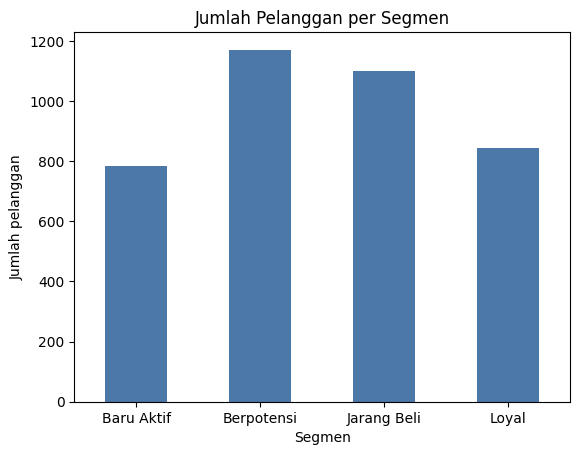

In [34]:
seg["count"].plot(kind="bar", color="#4C78A8")
plt.title("Jumlah Pelanggan per Segmen")
plt.xlabel("Segmen")
plt.ylabel("Jumlah pelanggan")
plt.xticks(rotation=0)
plt.show()

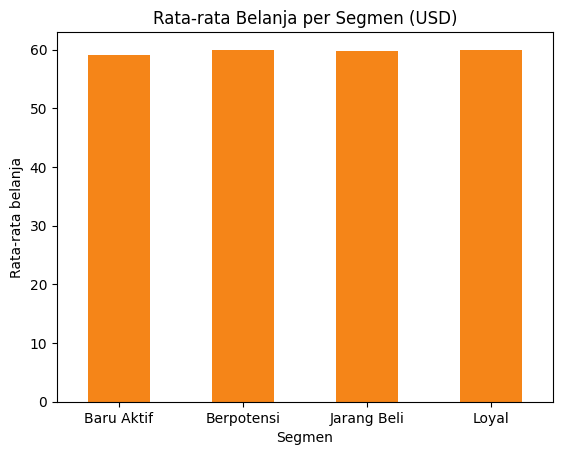

In [35]:
seg["mean"].plot(kind="bar", color="#F58518")
plt.title("Rata-rata Belanja per Segmen (USD)")
plt.xlabel("Segmen")
plt.ylabel("Rata-rata belanja")
plt.xticks(rotation=0)
plt.show()

In [36]:
customer.groupby("subscription_status")["purchase_amount"].agg(["count", "mean"]).round(1)

,count,mean
subscription_status,,
No,2847,59.9
Yes,1053,59.5


In [37]:
customer.groupby("discount_applied")["purchase_amount"].agg(["count", "mean"]).round(1)

,count,mean
discount_applied,,
No,2223,60.1
Yes,1677,59.3


In [38]:
seg = customer.groupby("segmen")["purchase_amount"].agg(["count", "mean", "sum"]).round(1)
seg["persen_pelanggan"] = (seg["count"] / seg["count"].sum() * 100).round(1)
seg["persen_belanja"] = (seg["sum"] / seg["sum"].sum() * 100).round(1)
seg

,count,mean,sum,persen_pelanggan,persen_belanja
segmen,,,,,
Baru Aktif,785,59.1,46429,20.1,19.9
Berpotensi,1171,60.0,70239,30.0,30.1
Jarang Beli,1101,59.8,65849,28.2,28.3
Loyal,843,60.0,50564,21.6,21.7
